# Doença em planta a partir de foto de drone

As pastas em `dados/treino` são as classes. O conjunto em `dados/teste` não tem
rótulo: serve para ver uma previsão, não para medir acurácia. A métrica sai de
um recorte de 20% das imagens rotuladas.

O InceptionV3 entra com pesos da ImageNet, sem a cabeça original. Só as últimas
50 camadas (e as de batch normalization) treinam. A GPU entra se o TensorFlow
a listar; a precisão mista reduz memória na RTX 3050. O OpenCV lê em BGR e o
gráfico converte para RGB.

In [2]:
import os
import pickle
import random
import cv2
import numpy as np
import tensorflow as tf 
from imutils import paths
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

SEED = 64
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if gpus:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("GPU:", gpus or "nenhuma, treino na CPU")

TAMANHO = (224, 224)

GPU: nenhuma, treino na CPU


In [3]:
def ler_imagens(pasta):
    imagens, classes = [], []
    for caminho in paths.list_images(pasta):
        imagem = cv2.imread(caminho)
        imagem = cv2.resize(imagem, TAMANHO)
        imagens.append(imagem.astype("float32") / 255.0)
        classes.append(caminho.split(os.path.sep)[-2])
    return np.array(imagens), np.array(classes)


X, nomes = ler_imagens("dados/treino")
print("imagens", X.shape, "MB %.1f" % (X.nbytes / 1024**2))

binarizador = LabelBinarizer()
y = binarizador.fit_transform(nomes)
os.makedirs("modelos", exist_ok=True)
pickle.dump(binarizador, open("modelos/binarizador_dsa.pickle", "wb"))

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_treino.shape, X_teste.shape, list(binarizador.classes_))

imagens (562, 224, 224, 3) MB 322.7
(449, 224, 224, 3) (113, 224, 224, 3) [np.str_('ferrugem_das_folhas'), np.str_('ferrugem_do_tronco'), np.str_('trigo_saudavel')]


## Modelo

Congelar o miolo da ImageNet e treinar o final evita reaprender bordas e texturas
já úteis, e cabe na placa. O checkpoint guarda o menor `val_loss`. Oito épocas
sem melhora encerram o treino antes das 25.

In [4]:
base = tf.keras.applications.InceptionV3(include_top=False, input_shape=(224, 224, 3), weights="imagenet")
saida = tf.keras.layers.GlobalAveragePooling2D()(base.output)
saida = tf.keras.layers.Dense(len(binarizador.classes_), activation="softmax", dtype="float32")(saida)
modelo = tf.keras.Model(base.input, saida)

for camada in modelo.layers[:-50]:
    if not isinstance(camada, tf.keras.layers.BatchNormalization):
        camada.trainable = False

caminho = "modelos/modelo_dsa.keras"
modelo.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
modelo.fit(
    X_treino,
    y_treino,
    validation_data=(X_teste, y_teste),
    epochs=25,
    batch_size=32,
    callbacks=[
        ModelCheckpoint(caminho, monitor="val_loss", save_best_only=True, mode="min"),
        EarlyStopping(monitor="val_loss", patience=8, mode="min"),
    ],
)

modelo = tf.keras.models.load_model(caminho)
prob = modelo.predict(X_teste, verbose=0)
y_hat = prob.argmax(axis=1)
y_real = y_teste.argmax(axis=1)
print("acurácia %.3f" % accuracy_score(y_real, y_hat))
print(classification_report(y_real, y_hat, target_names=list(binarizador.classes_)))

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.6392 - loss: 0.9285 - val_accuracy: 0.4248 - val_loss: 4.3942
Epoch 2/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9265 - loss: 0.1919 - val_accuracy: 0.3894 - val_loss: 8.1315
Epoch 3/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9933 - loss: 0.0433 - val_accuracy: 0.5487 - val_loss: 3.2588
Epoch 4/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9978 - loss: 0.0085 - val_accuracy: 0.5221 - val_loss: 3.9669
Epoch 5/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 0.5221 - val_loss: 3.7482
Epoch 6/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.6106 - val_loss: 2.8335
Epoch 7/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.6549 - val_loss: 2.1317
Epoch 8/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 1.000

## Foto nova

A pasta `dados/teste` não tem classe no nome. A função mostra a chance de cada classe.

ferrugem_das_folhas: 99.6%
ferrugem_do_tronco: 0.4%
trigo_saudavel: 0.0%


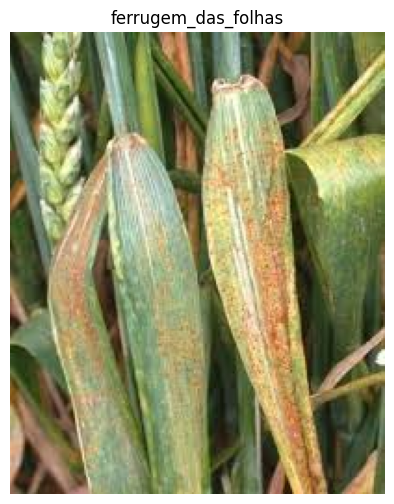

In [12]:
def classificar(arquivo):
    imagem = cv2.imread(arquivo)
    lote = cv2.resize(imagem, TAMANHO).astype("float32") / 255.0
    proba = modelo.predict(lote[None, ...], verbose=0)[0]
    for nome, chance in zip(binarizador.classes_, proba):
        print("%s: %.1f%%" % (nome, chance * 100))
    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB))
    plt.title(binarizador.classes_[int(proba.argmax())])
    plt.axis("off")
    plt.show()


pasta_teste = "dados/teste"
classificar(os.path.join(pasta_teste, random.choice(os.listdir(pasta_teste))))